In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import yaml
import yaml_include


yaml.add_constructor("!include", yaml_include.Constructor(base_dir="../configs"))

In [ ]:
sys.path.append("../")

In [18]:
from dataset import CMSDataset

In [13]:
with open("../configs/fm_impact.yaml", "r") as f:
    config = yaml.full_load(f)
data_config = config["data"]

In [19]:
ds = CMSDataset(
    data_config["valid_path"],
    data_config,
    data_config["scale_dict_path"],
    2000,
    entry_start=data_config["entry_start_valid"],
    mode="train",
)

 we have  2000  events


100%|██████████| 26/26 [00:00<00:00, 750.90it/s]


done loading data


In [20]:
data = ds[0]

In [35]:
pf_d0Sig_all = []
pf_mask_all = []

In [36]:
for i, data in enumerate(ds):
    pf_d0Sig_all.append(data[0][..., 1].numpy())
    pf_mask_all.append(data[1]["fs_mask"].numpy())
pf_d0Sig_all = np.concatenate(pf_d0Sig_all, axis=0)
pf_mask_all = np.concatenate(pf_mask_all, axis=0)

In [43]:
data_from_fm = np.load("../pf_d0Sig_mask_all.npz", allow_pickle=True)

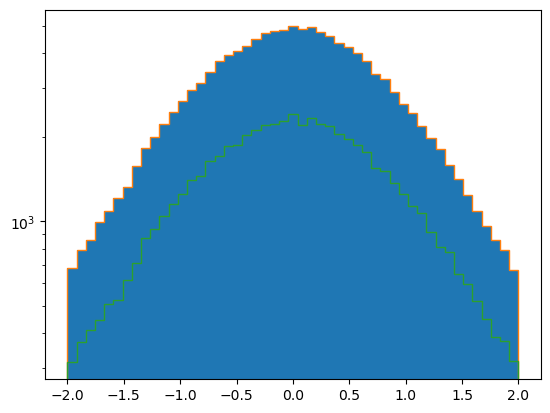

In [47]:
plt.hist(
    ds.full_data_array["pflow_d0Sig"][ds.full_data_array["pflow_class"] < 3],
    bins=np.linspace(-2, 2, 50),
    # density=True,
)
plt.hist(
    pf_d0Sig_all[pf_mask_all],
    bins=np.linspace(-2, 2, 50),
    histtype="step",
    # density=True,
)
plt.hist(
    data_from_fm["pf_d0Sig"],
    bins=np.linspace(-2, 2, 50),
    histtype="step",
)
plt.yscale("log")
plt.show()